# Explainable Next-Day Extreme Heat Prediction for Chennai

**Goal.** Predict tomorrow's (D+1) daily maximum air temperature in Chennai from weather observed up to
and including today (D), flag days that would be *unusually hot for Chennai* under a transparent,
project-defined seasonal threshold, and explain each prediction.

**This notebook** downloads NASA POWER data, checks data quality, explores the data, builds
leakage-safe features, tunes and compares Linear Regression, SVR and Random Forest against two baselines
using a chronological split, evaluates once on a held-out test period, explains the selected model and
saves everything the Streamlit app needs.

| Period (by **target** date) | Years | Used for |
|---|---|---|
| Training | 1981–2012 | fitting and time-series cross-validation |
| Validation | 2013–2018 | comparing tuned models and choosing one |
| Test | 2019–2025 | a single final evaluation after selection |
| Live | 2026 onward | the app only (never used for fitting) |

> NASA POWER is gridded reanalysis data, not station data. Nothing here is an India Meteorological
> Department (IMD) forecast or heat-wave alert.

**Run in Google Colab:** *Runtime → Run all*. Almost all the run time is the hyperparameter search
(26 SVR and Random Forest settings × 5 folds). On the author's 16-thread laptop the search took about 1.5 minutes on
mains power and about 26 minutes when throttled on battery. Colab's free runtime has fewer CPU cores, so
allow for a long search there (not measured). Set `RUN_TUNING = False` below to reuse the
hyperparameters recorded in `models/metadata.json` and skip the search.

## 0. Setup

In [1]:
# --- Settings ---------------------------------------------------------------
REPO_URL = "https://github.com/arpit-rath/Explainable-Heat-Prediction.git"
RUN_TUNING = True          # False = reuse hyperparameters recorded in models/metadata.json (fast)
DOWNLOAD_FRESH = True      # True = download 1981-2025 again from NASA POWER and compare with the snapshot
SAVE_ARTIFACTS = True      # overwrite models/ and outputs/ with this run's results

import os, sys, subprocess
from pathlib import Path

def find_repo():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src" / "heatpred").exists():
            return p
    return None

ROOT = find_repo()
if ROOT is None:  # e.g. a fresh Google Colab runtime
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    ROOT = Path.cwd() / "Explainable-Heat-Prediction"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: D:\SRM\5th Semester\Global Warming\Explainable-Heat-Prediction


In [2]:
import json, inspect, platform, random
import numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from heatpred import config as C, data as D, features as F, experiment as E, plots, explain as X
from heatpred.models import regression_metrics

random.seed(C.RANDOM_SEED); np.random.seed(C.RANDOM_SEED)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
%matplotlib inline
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__})

{'python': '3.12.6', 'numpy': '2.5.1', 'pandas': '2.3.3', 'scikit-learn': '1.9.0'}


## 1. Data source: NASA POWER Daily API

Facts checked against the official documentation and the API response header:

* **Endpoint:** `https://power.larc.nasa.gov/api/temporal/daily/point` (API version shown below).
* **Spatial resolution:** meteorology comes from the GMAO **MERRA-2** reanalysis on a **½° lat × ⅝° lon**
  grid (≈55 × 68 km), with **GEOS-IT** filling the most recent period at the same grid.
  ([sources](https://power.larc.nasa.gov/docs/methodology/data/sources_meteorology/))
* **Coverage:** daily data from **1 January 1981** to near real time.
* **Latency:** about **2–3 days** for meteorological parameters
  ([FAQ](https://power.larc.nasa.gov/docs/faqs/data/)). MERRA-2 values replace GEOS-IT values later.
* **Missing values:** the fill value is **−999** (reported in the response header as `fill_value`).
* **Time standard:** `LST` (local solar time, the API default, set explicitly). Daily Tmax/Tmin are the
  max/min of the 24 hourly values.
* **Community `AG`:** units are °C, %, g/kg, mm/day, m/s, degrees and kPa.

In [3]:
print("Exact, reproducible request:\n")
print(D.build_request_url(C.STUDY_START, C.STUDY_END))
print("\nParameters:", D.build_request_params(C.STUDY_START, C.STUDY_END))

Exact, reproducible request:

https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M_MAX,T2M_MIN,T2M,T2MDEW,RH2M,QV2M,PRECTOTCORR,WS2M,WD2M,PS&community=AG&longitude=80.2707&latitude=13.0827&start=19810101&end=20251231&format=JSON&time-standard=LST

Parameters: {'parameters': 'T2M_MAX,T2M_MIN,T2M,T2MDEW,RH2M,QV2M,PRECTOTCORR,WS2M,WD2M,PS', 'community': 'AG', 'longitude': '80.2707', 'latitude': '13.0827', 'start': '19810101', 'end': '20251231', 'format': 'JSON', 'time-standard': 'LST'}


In [4]:
snapshot, snap_meta = D.load_frame(C.SNAPSHOT_CSV, C.SNAPSHOT_META) if C.SNAPSHOT_CSV.exists() else (None, {})
if DOWNLOAD_FRESH:
    try:
        fresh, fresh_meta = D.download(C.STUDY_START, C.STUDY_END)
        print("Downloaded", fresh.shape, "API", fresh_meta["api_version"], "sources", fresh_meta["data_sources"])
        if snapshot is not None:
            diff = (fresh.round(2) - snapshot.reindex(fresh.index)).abs()
            print("Cells differing from bundled snapshot by > 0.01:", int((diff > 0.011).sum().sum()),
                  "(NASA can reprocess historical data; the bundled snapshot keeps results reproducible)")
        else:
            D.save_frame(fresh, fresh_meta, C.SNAPSHOT_CSV, C.SNAPSHOT_META); snapshot, snap_meta = fresh, fresh_meta
    except D.PowerAPIError as err:
        print("Download failed, using the bundled snapshot instead:", err)
daily, data_meta = D.load_frame(C.SNAPSHOT_CSV, C.SNAPSHOT_META)
print("Snapshot retrieved (UTC):", data_meta.get("retrieved_utc"))
print("Grid cell returned by the API (lon, lat, elevation m):", data_meta["grid_cell_geometry"]["coordinates"])
pd.DataFrame(data_meta["parameters"]).T

Downloaded (16436, 10) API v2.10.3 sources ['MERRA2', 'POWER']
Cells differing from bundled snapshot by > 0.01: 0 (NASA can reprocess historical data; the bundled snapshot keeps results reproducible)
Snapshot retrieved (UTC): 2026-11-10T15:59:00+00:00
Grid cell returned by the API (lon, lat, elevation m): [80.271, 13.083, 48.95]


,units,longname
T2M_MAX,C,Temperature at 2 Meters Maximum
T2M_MIN,C,Temperature at 2 Meters Minimum
T2M,C,Temperature at 2 Meters
T2MDEW,C,Dew/Frost Point at 2 Meters
RH2M,%,Relative Humidity at 2 Meters
QV2M,g/kg,Specific Humidity at 2 Meters
PRECTOTCORR,mm/day,Precipitation Corrected
WS2M,m/s,Wind Speed at 2 Meters
WD2M,Degrees,Wind Direction at 2 Meters
PS,kPa,Surface Pressure


## 2. Data quality assessment

In [5]:
q = D.quality_report(daily)
display(pd.Series({k: v for k, v in q.items() if not isinstance(v, dict)}, name="value").to_frame())
display(pd.DataFrame({"missing (−999)": q["missing_values_per_column"],
                      "outside physical range": q["out_of_physical_range_per_column"],
                      "unit": C.UNITS}))
daily.describe().T.round(2)

,value
rows,16436
columns,10
first_date,1981-01-01
last_date,2025-12-31
expected_days_in_range,16436
missing_calendar_dates,0
duplicate_dates,0
tmin_greater_than_tmax,0
tmean_outside_tmin_tmax,0


,missing (−999),outside physical range,unit
tmax,0,0,°C
tmin,0,0,°C
tmean,0,0,°C
dewpoint,0,0,°C
rh,0,0,%
qv,0,0,g/kg
precip,0,0,mm/day
wind_speed,0,0,m/s
wind_dir,0,0,degrees
pressure,0,0,kPa


,count,mean,std,min,25%,50%,75%,max
tmax,16436.0,32.23,3.55,22.99,29.07,32.21,35.02,43.34
tmin,16436.0,24.53,2.38,17.16,22.91,24.97,26.10,31.07
tmean,16436.0,27.87,2.66,21.11,25.74,28.05,29.86,35.33
dewpoint,16436.0,21.85,2.00,13.83,20.60,22.23,23.39,26.29
rh,16436.0,72.38,9.14,39.84,65.57,72.64,79.39,94.08
qv,16436.0,16.60,1.96,10.10,15.28,16.92,18.11,21.60
precip,16436.0,3.41,9.02,0.00,0.00,0.25,2.60,187.88
wind_speed,16436.0,3.16,0.94,0.79,2.51,3.08,3.73,11.28
wind_dir,16436.0,154.83,84.07,0.10,69.97,161.60,230.70,360.00
pressure,16436.0,100.31,0.37,99.06,100.00,100.27,100.62,101.28


**Is each feature available at prediction time?** A forecast for day D+1 is issued at the end of day D,
so it may use daily values for D and earlier days. In real-time use NASA POWER adds a 2–3 day delay; the
app therefore always shows the date of the latest data it used.

In [6]:
D.FEATURE_AVAILABILITY

,variable,used as,available at prediction time?
0,tmax,Max temperature of day D and earlier days,Yes - known after day D ends
1,tmin,Min temperature of day D and earlier,Yes
2,tmean,Mean temperature of day D,Yes
3,dewpoint,Dew point of day D,Yes
4,rh,Relative humidity of day D and earlier,Yes
5,qv,Specific humidity of day D,Yes
6,precip,Rainfall of day D and earlier,Yes
7,wind_speed / wind_dir,Wind of day D,Yes
8,pressure,Surface pressure of day D and earlier,Yes
9,calendar,Day-of-year of the target day D+1,Yes - the calendar is always known


**Gridded vs station data.** These values are averages over a ≈55 × 68 km cell that includes sea and
inland areas. They are smoother than readings at the IMD stations (Nungambakkam, Meenambakkam). Peak
values in particular can differ by a degree or more, so results describe the grid cell, not one
thermometer.

## 3. Exploratory data analysis

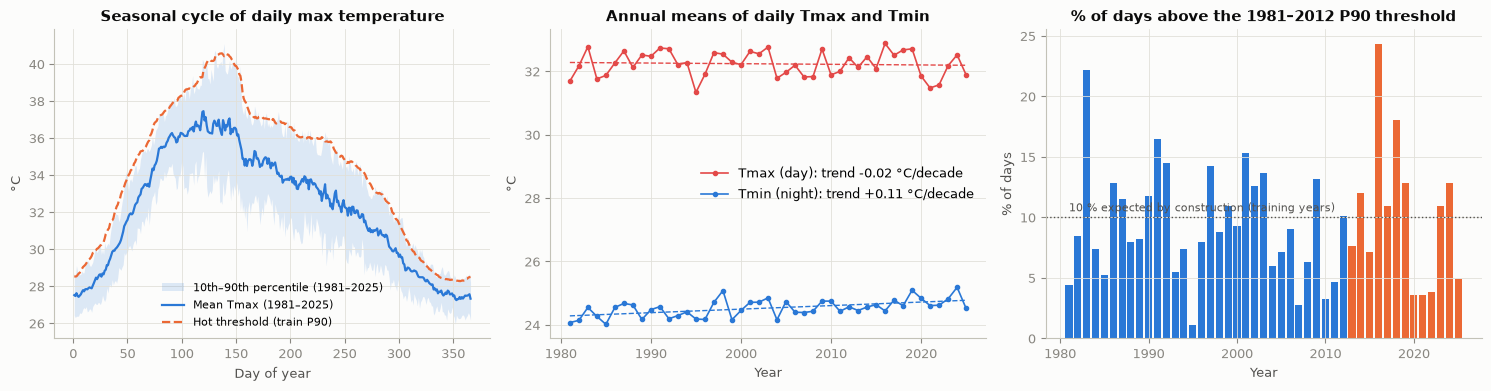

Days above the 1981-2012 P90: 9.4% (1981-2012), 13.4% (2013-2018), 7.5% (2019-2025)


,unit,OLS trend per decade,mean 1981-2012,mean 2013-2025
variable,,,,
tmax,°C,-0.020,32.239,32.225
tmin,°C,0.112,24.458,24.704
tmean,°C,0.063,27.826,27.969
rh,%,0.654,71.965,73.408
qv,g/kg,0.246,16.438,16.988
precip,mm/day,0.190,3.297,3.676


In [7]:
exp = E.prepare()                      # leakage-safe feature table (see section 4)
threshold = E.fit_threshold(exp)       # seasonal P90 from TRAINING target days only
fig, eda = plots.eda_overview(daily, threshold); plt.show()
ex = eda["exceedance_pct_by_year"]
print(f"Days above the 1981-2012 P90: {ex.loc[1981:2012].mean():.1f}% (1981-2012), "
      f"{ex.loc[2013:2018].mean():.1f}% (2013-2018), {ex.loc[2019:2025].mean():.1f}% (2019-2025)")
rows = []
for col in ["tmax", "tmin", "tmean", "rh", "qv", "precip"]:
    annual = daily[col].groupby(daily.index.year).mean()
    rows.append({"variable": col, "unit": C.UNITS[col],
                 "OLS trend per decade": np.polyfit(annual.index, annual.values, 1)[0] * 10,
                 "mean 1981-2012": annual.loc[1981:2012].mean(), "mean 2013-2025": annual.loc[2013:2025].mean()})
pd.DataFrame(rows).set_index("variable").round(3)

*Reading the charts and the table.* Chennai's hottest period is **April–June**, before the
southwest-monsoon clouds arrive. The northeast monsoon (Oct–Dec) is the coolest and wettest period.

Over 1981–2025, this NASA POWER grid cell shows **almost no linear trend in daytime maximum
temperature**. **Night-time minimum temperature and humidity have risen.** For a humid coastal city
this matters: warmer, more humid nights raise heat stress even when daytime maxima do not climb. This is
a simple least-squares description of one gridded dataset (no significance test). Reanalysis trends for
a single cell can differ from IMD station trends, which this project did not analyse, and nothing here
attributes any individual hot day to climate change.

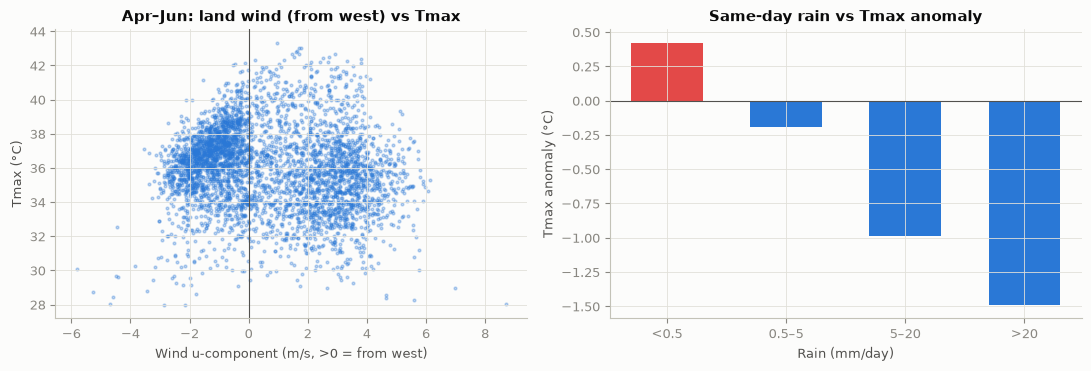

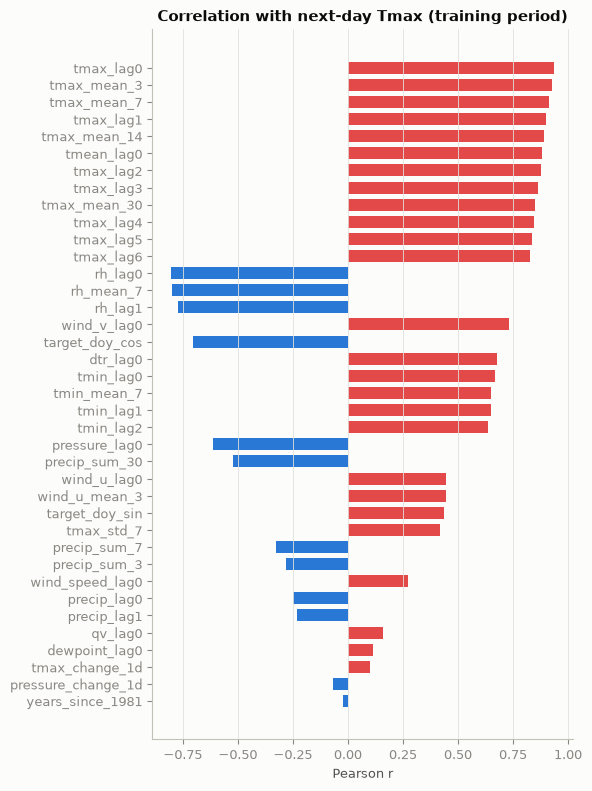

In [8]:
fig = plots.monthly_relationships(daily); plt.show()
fig, corr = plots.correlation_with_target(exp.table, F.TARGET, F.RAW_FEATURES); plt.show()

*Physical principles and what this dataset does or does not show:*
1. **Persistence.** Air masses, soil moisture and sea-surface temperature change slowly, so tomorrow
   resembles today. The day-to-day autocorrelation of the Tmax anomaly is 0.73.
2. **Clouds and rain** cut incoming sunshine and cool the surface through evaporation. Days with more
   than 20 mm of rain average about 1.5 °C below the seasonal normal (right panel).
3. **Seasonality:** the sun's angle and the monsoon cycle (left panel of the EDA figure).
4. **Land vs sea breeze.** In meteorology, offshore westerly winds bring hot continental air to
   Chennai's east-facing coast, and sea breezes moderate the maximum. In this gridded *daily-mean* wind,
   however, April–June days with a westerly component are **not** hotter on average (left panel). Daily
   means blur the sea-breeze cycle, and the westerly monsoon flow in June arrives with cloud. So the wind
   inputs should be read as statistical predictors, not a demonstration of the land-wind effect.

## 4. Features without leakage

Each row is an *issue date* D. Every feature uses values from D or earlier: lags 0–6 days, rolling
windows **ending on D**, day-to-day changes, wind vector components, and the calendar position of D+1.
The target is `tmax` shifted by −1 day, the only forward-looking column, and it is never an input.

Learned statistics are **inside the scikit-learn pipeline**, so they are fitted on training rows only
(and re-fitted inside every CV fold):
`ClimatologyTransformer` (seasonal normal of Tmax → `clim_tmax_target`, anomalies) → `SimpleImputer(median)` →
`StandardScaler` → model.

In [9]:
print(inspect.getsource(F.build_feature_table)[:2500], "...")
print("\nModel inputs (%d):" % len(F.MODEL_FEATURES), F.MODEL_FEATURES)

def build_feature_table(daily: pd.DataFrame) -> pd.DataFrame:
    """Return one row per issue date D with features (<= D) and the target (D+1).

    ``daily`` must be indexed by date. Missing calendar days are inserted as
    NaN so that a lag of k rows is always a lag of k days.
    """
    d = daily.sort_index()
    d = d[~d.index.duplicated(keep="last")]
    d = d.reindex(pd.date_range(d.index.min(), d.index.max(), freq="D"))
    d.index.name = "issue_date"

    # Wind components (meteorological convention: direction wind blows FROM).
    theta = np.deg2rad(d["wind_dir"])
    wind_u = -d["wind_speed"] * np.sin(theta)   # > 0 : westerly (from land, Chennai coast faces east)
    wind_v = -d["wind_speed"] * np.cos(theta)   # > 0 : southerly

    f = pd.DataFrame(index=d.index)
    for k in range(7):
        f[f"tmax_lag{k}"] = d["tmax"].shift(k)
    f["tmax_change_1d"] = d["tmax"] - d["tmax"].shift(1)
    for w in (3, 7, 14, 30):
        f[f"tmax_mean_{w}"] = _rolling(d["tmax"], w, "me

In [10]:
# Leakage check: change every value AFTER a cut-off day; features on/before that day must not change.
cut = pd.Timestamp("2015-06-01")
tampered = daily.copy(); tampered.loc[tampered.index > cut] += 25
a = F.build_feature_table(daily).loc[:cut, F.RAW_FEATURES]
b = F.build_feature_table(tampered).loc[:cut, F.RAW_FEATURES]
print("Features up to the cut-off unchanged by future data:", a.equals(b))

Features up to the cut-off unchanged by future data: True


In [11]:
E.split_summary(exp)

,rows,first target date,last target date,mean target Tmax (°C)
split,,,,
train,11657,1981-02-01,2012-12-31,32.25
validation,2191,2013-01-01,2018-12-31,32.45
test,2557,2019-01-01,2025-12-31,32.03


## 5. Project-defined heat indicator

A day is **"unusually hot for Chennai"** if its maximum temperature exceeds the **90th percentile** of
training-period (1981–2012) maximum temperatures **within ±7 days of the same calendar date**. The
threshold is computed from training target days only. It is a project indicator, **not** IMD's heat-wave
criterion, which uses station data, departure from normal and absolute thresholds.

In [12]:
thr_month = threshold.groupby(pd.to_datetime(threshold.index - 1, unit="D", origin="2001-01-01").month).mean()
display(thr_month.round(1).rename("mean P90 threshold (°C)").to_frame().T)

doy,1,2,3,4,5,6,7,8,9,10,11,12
mean P90 threshold (°C),29.5,33.1,36.5,38.6,40.3,37.6,36.6,35.8,34.5,32.4,29.5,28.4


## 6. Baselines, candidate models and time-series tuning

* **Persistence:** tomorrow = today.
* **Seasonal average:** tomorrow = training-period mean Tmax for that calendar day (±7-day window).
* **Linear Regression**, **SVR (RBF kernel)**, **Random Forest**, each in the same pipeline.

Hyperparameters are tuned with `TimeSeriesSplit(n_splits=5, gap=30)` **inside 1981–2012 only**.
Each fold trains on earlier years and validates on later years, with a 30-day gap so rolling windows
cannot overlap.

In [13]:
if RUN_TUNING:
    tuning_table = E.tune_candidates(exp)
else:
    tuning_table = E.use_recorded_tuning(exp)
tuning_table[["best_params", "cv_mae", "cv_mae_std", "n_candidates"]]

Linear Regression  CV MAE 0.859 ± 0.051 °C (1 candidates, 1.9 s) {}


SVR (RBF)          CV MAE 0.818 ± 0.035 °C (18 candidates, 714.8 s) {'model__C': 30.0, 'model__epsilon': 0.5, 'model__gamma': 0.002}


Random Forest      CV MAE 0.834 ± 0.031 °C (8 candidates, 843.6 s) {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 20}


,best_params,cv_mae,cv_mae_std,n_candidates
model,,,,
Linear Regression,{},0.858599,0.050882,1
SVR (RBF),"{'model__C': 30.0, 'model__epsilon': 0.5, 'mod...",0.817670,0.034979,18
Random Forest,"{'model__n_estimators': 200, 'model__min_sampl...",0.833948,0.030508,8


## 7. Validation (2013–2018) and model selection

**Rule, fixed before the test period is scored:** choose the ML candidate with the lowest validation
MAE, *unless* a simpler, more interpretable candidate is within 0.05 °C, in which case prefer it
(order of simplicity: Linear Regression → Random Forest → SVR).

In [14]:
val = E.validation_comparison(exp)
display(val.round(3))
print("Selected model:", exp.selected)

,MAE,MSE,RMSE,R2,Bias (pred - actual),n
Persistence (tomorrow = today),0.903,1.715,1.310,0.845,0.001,2191.0
Seasonal average,1.304,2.883,1.698,0.739,-0.214,2191.0
Linear Regression,0.811,1.322,1.150,0.880,-0.056,2191.0
SVR (RBF),0.788,1.275,1.129,0.885,-0.028,2191.0
Random Forest,0.802,1.284,1.133,0.884,-0.073,2191.0


Selected model: Linear Regression


### Chance of an unusually hot day (heat flag)

A single best-guess temperature hides uncertainty. The model's out-of-fold errors in the training-period
cross-validation give an error spread σ for each month, so
`P(hot) = 1 − Φ((threshold − prediction) / σ_month)`. The flag is raised when `P(hot)` is at least a
cut-off chosen **on the validation years** by maximum F1, and is then frozen.

In [15]:
print("Error SD by target month (°C):", {k: round(v, 2) for k, v in exp.heat["sigma_by_month"].items()})
print("Chosen cut-off:", exp.heat["cutoff"])
display(exp.val_cutoff_table.round(3))
print("Validation calibration (are the chances honest?):")
exp.val_calibration.round(3)

Error SD by target month (°C): {1: 0.63, 2: 0.71, 3: 0.85, 4: 1.23, 5: 1.65, 6: 1.61, 7: 1.38, 8: 1.37, 9: 1.27, 10: 1.1, 11: 0.76, 12: 0.61}
Chosen cut-off: 0.35


,cutoff,hot_days,flagged_days,hits,missed,false_alarms,recall (hit rate),precision,F1
0,0.10,293,782,271,22,511,0.925,0.347,0.504
1,0.15,293,622,255,38,367,0.870,0.410,0.557
2,0.20,293,500,238,55,262,0.812,0.476,0.600
3,0.25,293,414,218,75,196,0.744,0.527,0.617
4,0.30,293,336,194,99,142,0.662,0.577,0.617
5,0.35,293,279,182,111,97,0.621,0.652,0.636
6,0.40,293,232,164,129,68,0.560,0.707,0.625
7,0.45,293,197,147,146,50,0.502,0.746,0.600
8,0.50,293,159,130,163,29,0.444,0.818,0.575
9,0.55,293,127,109,184,18,0.372,0.858,0.519


Validation calibration (are the chances honest?):


,days,mean_predicted_chance,observed_frequency
"(-0.001, 0.1]",1409,0.021,0.016
"(0.1, 0.2]",282,0.145,0.117
"(0.2, 0.3]",164,0.247,0.268
"(0.3, 0.5]",177,0.390,0.362
"(0.5, 0.7]",78,0.582,0.705
"(0.7, 1.0]",81,0.876,0.926


**Design history (reported openly).** Design v1 had no long-term trend input and raised the heat flag
only when the predicted value crossed the threshold. When the test years were first scored, that flag
caught only 17 % of hot days (log: `outputs/run_logs/run1_design_v1.txt`). Two changes were then tested
**on the validation years only**: a calendar-based trend input (`years_since_1981`), which lowered
validation MAE from 0.820 to 0.811 °C and the bias from −0.13 to −0.06 °C, and the probability-based flag.
Seasonal interaction terms were also tried and rejected because they gave almost no gain (0.810). The
test years were then scored a second time with design v2 (this notebook; log
`outputs/run_logs/run2_design_v2.txt`).

## 8. Final evaluation on the untouched test period (2019–2025)

Every model and baseline is refitted on 1981–2018 with its tuned settings and scored **once** on
2019–2025.

,MAE,MSE,RMSE,R2,Bias (pred - actual),n
Persistence (tomorrow = today),0.854,1.456,1.207,0.868,-0.000,2557.0
Seasonal average,1.195,2.511,1.584,0.772,0.246,2557.0
Linear Regression,0.766,1.118,1.058,0.899,0.006,2557.0
SVR (RBF),0.741,1.069,1.034,0.903,0.054,2557.0
Random Forest,0.754,1.090,1.044,0.901,-0.075,2557.0


Linear Regression test MAE 0.766 °C vs best baseline 0.854 °C -> 10.3% lower error


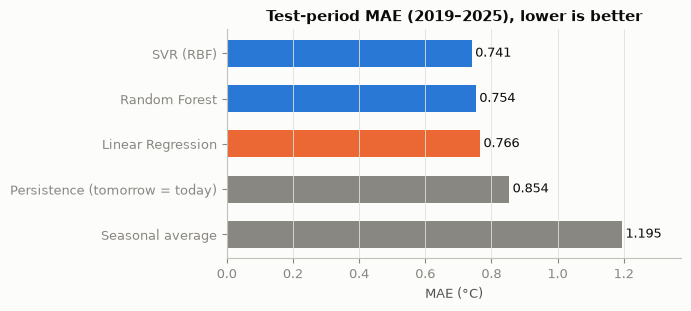

In [16]:
test_metrics = E.final_test_evaluation(exp)
display(test_metrics[["MAE", "MSE", "RMSE", "R2", "Bias (pred - actual)", "n"]].round(3))
best_baseline = test_metrics.loc[E.BASELINES, "MAE"].min()
sel_mae = test_metrics.loc[exp.selected, "MAE"]
print(f"{exp.selected} test MAE {sel_mae:.3f} °C vs best baseline {best_baseline:.3f} °C "
      f"-> {100 * (1 - sel_mae / best_baseline):.1f}% lower error")
fig = plots.model_comparison(test_metrics, exp.selected); plt.show()

In [17]:
print("Errors on the test days that were actually unusually hot (actual Tmax > seasonal P90):")
display(exp.test_hot_metrics.round(3))
print("Heat-flag skill on the test period:")
display(exp.test_flag_metrics.round(3))
print("Test calibration:")
exp.test_calibration.round(3)

Errors on the test days that were actually unusually hot (actual Tmax > seasonal P90):


,hot_days,MAE_on_hot_days,Bias_on_hot_days,hit_rate (recall),precision,false_alarms,missed
Persistence (tomorrow = today),192.0,0.824,-0.594,0.500,0.487,101.0,96.0
Seasonal average,192.0,2.220,-2.220,0.000,NaN,0.0,192.0
Linear Regression,192.0,1.073,-1.052,0.234,0.703,19.0,147.0
SVR (RBF),192.0,0.958,-0.920,0.286,0.625,33.0,137.0
Random Forest,192.0,1.074,-1.035,0.245,0.681,22.0,145.0


Heat-flag skill on the test period:


,hot_days,flagged_days,hits,missed,false_alarms,recall (hit rate),precision,F1,Brier score
Persistence: today's Tmax above threshold,192.0,197.0,96.0,96.0,101.0,0.500,0.487,0.494,NaN
Linear Regression: predicted Tmax above threshold,192.0,64.0,45.0,147.0,19.0,0.234,0.703,0.352,NaN
Linear Regression: chance of hot day >= 35% (deployed flag),192.0,163.0,84.0,108.0,79.0,0.438,0.515,0.473,0.05


Test calibration:


,days,mean_predicted_chance,observed_frequency
"(-0.001, 0.1]",1896,0.018,0.010
"(0.1, 0.2]",287,0.141,0.132
"(0.2, 0.3]",149,0.249,0.221
"(0.3, 0.5]",161,0.377,0.354
"(0.5, 0.7]",48,0.575,0.646
"(0.7, 1.0]",16,0.795,0.875


*Honest reading.* Every regression model under-predicts the days that turn out extreme by about 1 °C.
It is pulled toward typical values, and conditioning on extreme outcomes favours "tomorrow = today".
The probability flag catches far more hot days than the plain "prediction above threshold" rule and its
chances are well calibrated, but on the test years it still does **not** beat persistence on F1.

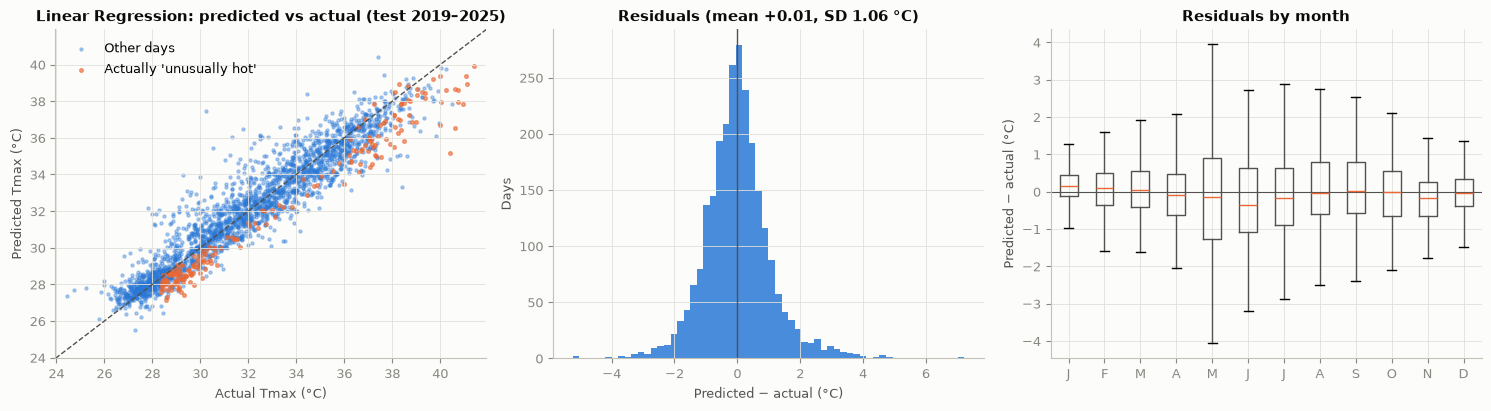

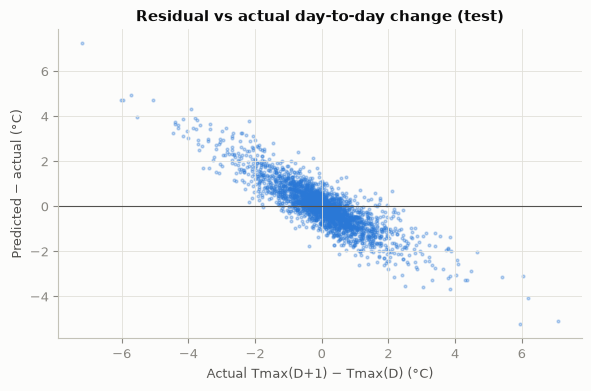

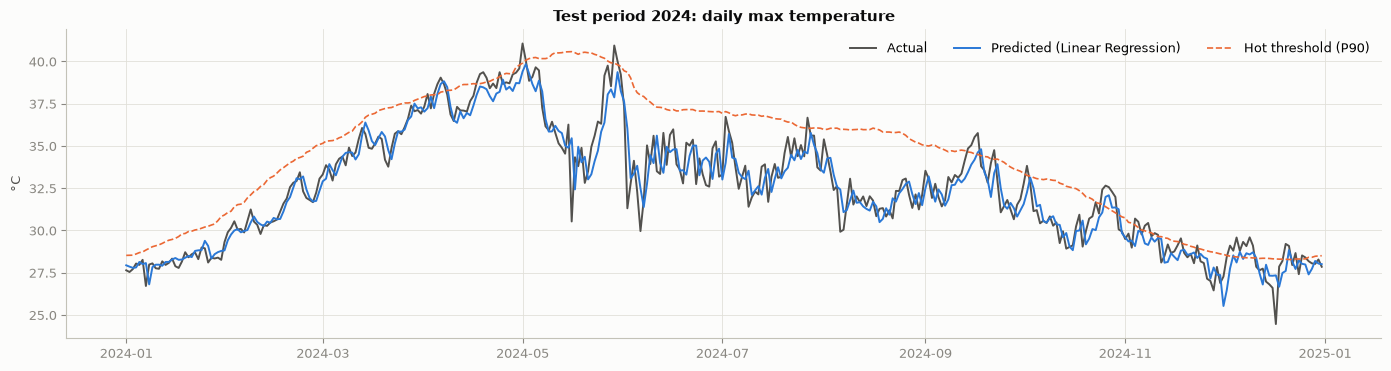

In [18]:
fig = plots.pred_vs_actual(exp.test_predictions, exp.selected); plt.show()
fig = plots.residual_vs_change(exp.test_predictions, exp.selected, exp.part("test")["tmax_lag0"]); plt.show()
fig = plots.time_series(exp.test_predictions, exp.selected, 2024); plt.show()

In [19]:
# Where are the biggest errors?
tp = exp.test_predictions.copy(); tp["error"] = tp[exp.selected] - tp["actual"]
tp["abs_error"] = tp.error.abs()
display(tp.nlargest(8, "abs_error")[["target_date", "actual", exp.selected, "error", "threshold_p90"]].round(2))
tp["month"] = pd.to_datetime(tp.target_date).dt.month
tp.groupby("month")["abs_error"].mean().round(3).rename("test MAE by month (°C)").to_frame().T

,target_date,actual,Linear Regression,error,threshold_p90
issue_date,,,,,
2023-06-06,2023-06-07,30.24,37.46,7.22,38.00
2019-05-01,2019-05-02,40.39,35.15,-5.24,39.90
2021-05-25,2021-05-26,38.40,33.33,-5.07,40.25
2024-05-15,2024-05-16,30.53,35.45,4.92,40.58
2023-06-16,2023-06-17,31.77,36.50,4.73,37.15
2024-06-01,2024-06-02,31.31,36.03,4.72,39.36
2023-07-01,2023-07-02,29.26,33.97,4.71,36.92
2021-08-20,2021-08-21,27.81,32.15,4.34,35.82


month,1,2,3,4,5,6,7,8,9,10,11,12
test MAE by month (°C),0.388,0.477,0.579,0.743,1.289,1.17,0.985,0.925,0.811,0.718,0.601,0.49


**Why not a random split?** For contrast only, the cell below scores Linear Regression on a *random*
80/20 split. Neighbouring days are strongly correlated, so a random split puts near-duplicate days on
both sides and also mixes future years into training. The score usually looks a little better than the
honest chronological test. **It is not used for any decision.**

In [20]:
from sklearn.model_selection import train_test_split
from heatpred.models import build_estimator
Xall, yall = exp.Xy("train", "validation", "test")
Xa, Xb, ya, yb = train_test_split(Xall, yall, test_size=0.2, random_state=C.RANDOM_SEED)
rnd = regression_metrics(yb, build_estimator("Linear Regression").fit(Xa, ya).predict(Xb))
print(f"Random-split MAE {rnd['MAE']:.3f} °C (optimistic, for illustration) vs chronological test MAE "
      f"{test_metrics.loc['Linear Regression', 'MAE']:.3f} °C")

Random-split MAE 0.818 °C (optimistic, for illustration) vs chronological test MAE 0.766 °C


## 9. Explainability

**Global.** (a) Standardised coefficients of the linear model: the °C change in the prediction for a one
standard-deviation increase in a feature, holding the others fixed. (b) Permutation importance on the
test period, which works for any model: how much MAE worsens when one feature is shuffled. Features such
as the recent-temperature lags are strongly correlated, so their individual coefficients can offset each
other. Grouped effects are easier to interpret.

**Local.** The linear model's prediction decomposes *exactly* as
`base + Σ coefᵢ·(zᵢ − zᵢ,normal)`. Here `base` is the model's prediction for an average 1981–2018 day at
the same time of year (±7 days), and z are standardised inputs. Each term shows how much that input's
departure from normal moved the prediction. These are **associations learned from data, not causal
effects**. With correlated inputs, an individual group's sign can look counter-intuitive, because each
effect is conditional on all the other inputs.

,feature,group,coef_per_SD (°C),training SD,coef_per_unit
0,tmean_lag0,Recent temperatures,2.320,2.695,0.861
1,qv_lag0,Humidity & moisture,-1.483,1.926,-0.770
2,clim_tmax_target,Time of year,1.134,3.106,0.365
3,rh_lag0,Humidity & moisture,0.859,9.188,0.093
4,wind_u_lag0,Wind (sea breeze vs land wind),0.689,2.376,0.290
5,target_doy_cos,Time of year,0.448,0.706,0.634
6,wind_u_mean_3,Wind (sea breeze vs land wind),-0.401,2.312,-0.174
7,dewpoint_lag0,Humidity & moisture,0.369,1.980,0.186
8,dtr_lag0,Recent temperatures,0.284,2.593,0.110
9,wind_v_lag0,Wind (sea breeze vs land wind),0.218,2.220,0.098


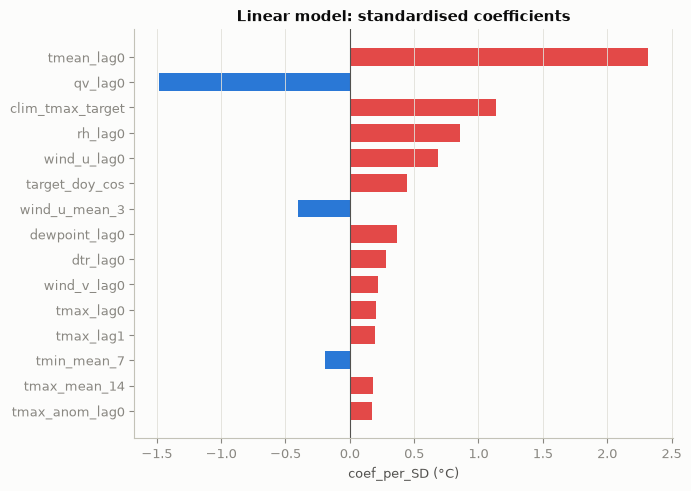

,feature,MAE increase (°C),std
0,tmean_lag0,1.794,0.010
1,qv_lag0,1.130,0.024
2,target_doy,0.802,0.005
3,rh_lag0,0.433,0.012
4,wind_u_lag0,0.318,0.007
5,tmax_lag0,0.237,0.006
6,target_doy_cos,0.151,0.005
7,dewpoint_lag0,0.146,0.009
8,wind_u_mean_3,0.102,0.004
9,dtr_lag0,0.070,0.006


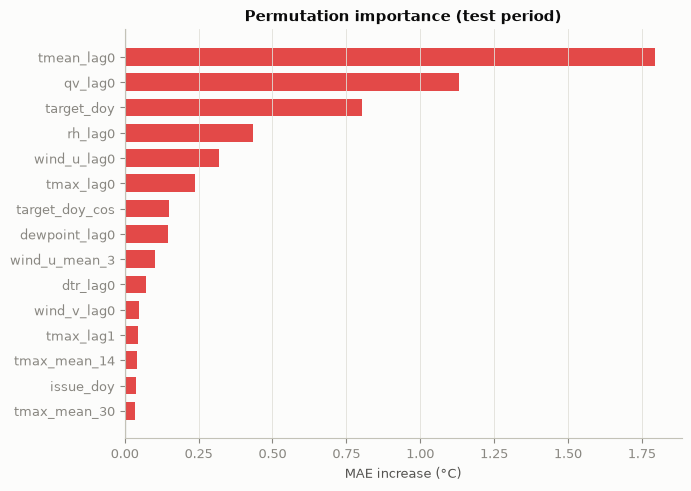

In [21]:
final = exp.final_models[exp.selected]
if hasattr(final.named_steps["model"], "coef_"):
    coefs = X.linear_coefficients(final)
    display(coefs.head(15).round(3))
    fig = plots.bar_importance(coefs, "coef_per_SD (°C)", "Linear model: standardised coefficients", "linear_coefficients"); plt.show()
imp = E.permutation_importance_table(exp)
display(imp.head(12).round(3))
fig = plots.bar_importance(imp, "MAE increase (°C)", "Permutation importance (test period)", "permutation_importance"); plt.show()

In [22]:
from heatpred.predict import predict_for_target_date
hottest = exp.test_predictions.sort_values("actual").iloc[-1]["target_date"]
from heatpred.heat import hot_probability
reference = X.seasonal_reference(final, exp.Xy("train", "validation")[0])   # normal day per calendar date
for day in [pd.Timestamp(hottest), pd.Timestamp("2023-11-20")]:
    res = predict_for_target_date(final, daily, day)
    base, table = X.explain_row(final, res["features"], reference)
    t = threshold.loc[day.dayofyear]
    sd = exp.heat["sigma_by_month"][day.month]
    chance = float(hot_probability([res["prediction"]], [t], [day.month], exp.heat["sigma_by_month"])[0])
    normal = table.loc[table.feature == "clim_tmax_target", "value"].item()
    display(Markdown(f"### {day:%d %b %Y}: predicted {res['prediction']:.2f} °C, actual {res['actual']:.2f} °C"))
    display(Markdown("\n".join(X.plain_language(base, res["prediction"], table, t, normal, chance, sd))))
    display(X.group_contributions(table).round(3))
    print("Check: base + contributions =", round(base + table.contribution.sum(), 3), "| prediction =", res["prediction"])

### 03 May 2019: predicted 39.93 °C, actual 41.42 °C

The model expects **39.9 °C**, which is 3.1 °C warmer than the 1981–2018 average of 36.8 °C for this date.
Starting point: on a normal day at this time of year (1981–2018 average conditions) the model would predict 36.7 °C. How the latest conditions differ from normal moves it to 39.9 °C:
- **Recent temperatures** raised the prediction by about 2.8 °C (largest single factor: mean temperature on day D was 33.5 °C vs a normal 31.3).
- **Wind (sea breeze vs land wind)** raised the prediction by about 0.7 °C (largest single factor: west-to-east wind component on D (positive = wind from the land/west) was 1.8 m/s vs a normal -0.7).
- **Humidity & moisture** lowered the prediction by about 0.5 °C (largest single factor: relative humidity on day D was 55.3 % vs a normal 64.4).
The best guess is below the project's 'unusually hot for Chennai' line of 40.1 °C for this date. Because the model's typical error in this month is about ±1.6 °C, the chance that the actual value ends up above the line is about 47%.
These effects are patterns learned from past data (associations), not proof of cause.

,group,contribution
0,Recent temperatures,2.815
1,Wind (sea breeze vs land wind),0.746
2,Humidity & moisture,-0.462
3,Slow drift across years,0.103
4,Surface pressure,0.053
5,Rainfall,0.018
6,Time of year,0.005


Check: base + contributions = 39.93 | prediction = 39.93


### 20 Nov 2023: predicted 29.04 °C, actual 27.89 °C

The model expects **29.0 °C**, which is 0.7 °C warmer than the 1981–2018 average of 28.3 °C for this date.
Starting point: on a normal day at this time of year (1981–2018 average conditions) the model would predict 28.3 °C. How the latest conditions differ from normal moves it to 29.0 °C:
- **Recent temperatures** raised the prediction by about 1.7 °C (largest single factor: mean temperature on day D was 27.0 °C vs a normal 25.4).
- **Humidity & moisture** lowered the prediction by about 1.0 °C (largest single factor: specific humidity (water vapour content) on day D was 18.8 g/kg vs a normal 16.6).
- **Wind (sea breeze vs land wind)** lowered the prediction by about 0.2 °C (largest single factor: west-to-east wind component on D (positive = wind from the land/west) was -2.5 m/s vs a normal -1.8).
The best guess is below the project's 'unusually hot for Chennai' line of 29.2 °C for this date. Because the model's typical error in this month is about ±0.8 °C, the chance that the actual value ends up above the line is about 43%.
These effects are patterns learned from past data (associations), not proof of cause.

,group,contribution
0,Recent temperatures,1.723
1,Humidity & moisture,-0.977
2,Wind (sea breeze vs land wind),-0.208
3,Slow drift across years,0.124
4,Rainfall,0.119
5,Time of year,0.004
6,Surface pressure,0.004


Check: base + contributions = 29.044 | prediction = 29.04


## 10. Save artifacts for the app

* `models/final_model.joblib`: the selected pipeline, fitted on 1981–2018
* `models/metadata.json`: metrics, splits, hyperparameters, data provenance, library versions
* `models/hot_threshold_p90.csv`: the seasonal heat threshold (from training data)
* `outputs/backtest_predictions.csv`: for every target date 1981–2025, the deployed model's
  prediction from the previous day's features, the two baselines, the actual value and the split label.
  Rows before 2019 are in-sample for the deployed model and are labelled as such.

In [23]:
if SAVE_ARTIFACTS:
    meta = E.save_artifacts(exp, imp)
    print("Saved. Deployed model:", meta["deployed_model"])
    print(json.dumps(meta["versions"], indent=1))
bt = pd.read_csv(C.BACKTEST_CSV); bt.tail()

Saved. Deployed model: {'name': 'Linear Regression', 'fitted_on': 'train + validation target dates (1981-2012 and 2013-2018)', 'hyperparameters': {}}
{
 "python": "3.12.6",
 "numpy": "2.5.1",
 "pandas": "2.3.3",
 "scikit-learn": "1.9.0",
 "scipy": "1.18.0",
 "joblib": "1.5.3",
 "requests": "2.34.2"
}


,issue_date,target_date,split,actual_tmax,predicted_tmax,persistence,seasonal_average,threshold_p90,error,hot_probability,hot_flag,actually_hot,in_sample_for_deployed_model
16400,2025-12-26,2025-12-27,test,27.53,27.47,27.11,27.40,28.32,-0.06,0.083,False,False,False
16401,2025-12-27,2025-12-28,test,27.45,27.67,27.53,27.42,28.41,0.22,0.114,False,False,False
16402,2025-12-28,2025-12-29,test,27.14,27.55,27.45,27.43,28.41,0.41,0.081,False,False,False
16403,2025-12-29,2025-12-30,test,26.95,27.29,27.14,27.43,28.47,0.34,0.027,False,False,False
16404,2025-12-30,2025-12-31,test,27.82,27.52,26.95,27.44,28.49,-0.30,0.057,False,False,False


## 11. Summary and limitations

* All three ML models beat both baselines on validation and test. The improvement over persistence is
  real but modest: next-day maximum temperature is highly persistent.
* The deployed model is chosen by a pre-declared rule that favours interpretability when accuracy is
  similar.
* Errors are largest on days with sudden changes (rain onset, wind shifts, cyclones), which a
  one-day-history statistical model cannot anticipate.
* Data are gridded reanalysis values, not station observations. The heat indicator is project-defined,
  not an IMD alert. Explanations are associations, not causes.
* In this grid cell daytime maxima show no clear 1981–2025 trend, while night-time minima and humidity
  rise. Nothing here attributes any single day to climate change.